# 18. Write a python program to apply hit-or-miss transform, thinning, or boundary extraction.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [12]:
# Read grayscale image
img = cv2.imread("image.jpeg", cv2.IMREAD_GRAYSCALE)

In [13]:
# Convert to binary
_, binary = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

rows, cols = binary.shape

In [14]:
# Erosion
erosion = np.zeros((rows, cols), dtype=np.uint8)

for i in range(1, rows-1):
    for j in range(1, cols-1):

        if np.all(binary[i-1:i+2, j-1:j+2] == 255):
            erosion[i, j] = 255

In [15]:
# Boundary extraction
boundary = np.zeros((rows, cols), dtype=np.uint8)

for i in range(rows):
    for j in range(cols):

        if binary[i, j] == 255 and erosion[i, j] == 0:
            boundary[i, j] = 255

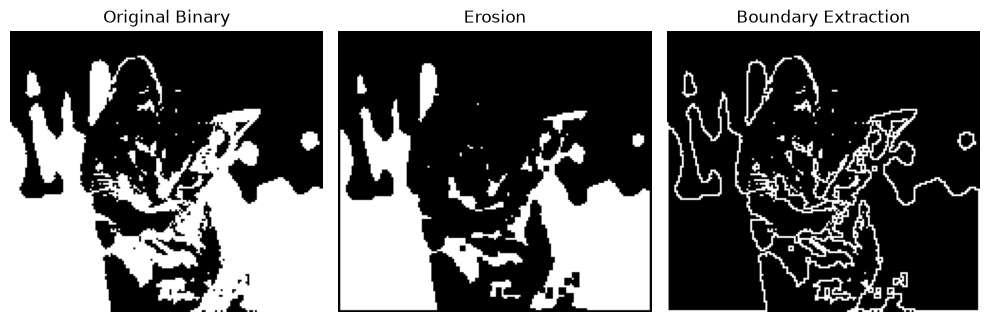

In [16]:
# Display results
plt.figure(figsize=(10, 4))

plt.subplot(1, 3, 1)
plt.imshow(binary, cmap='gray')
plt.title('Original Binary')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(erosion, cmap='gray')
plt.title('Erosion')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(boundary, cmap='gray')
plt.title('Boundary Extraction')
plt.axis('off')

plt.tight_layout()
plt.show()